# CV06 Tracking

### Lab Description
This laboratory exercise introduces an **object tracking pipeline** using `YOLOv8`, enabling real-time multi-object tracking on input videos.
Rather than training a new model, we directly apply a pretrained YOLOv8 detector along with a tracker (e.g., ByteTrack) to detect objects and assign unique identities across frames.

The workflow includes:
- Loading a pretrained YOLOv8 detector
- Performing object detection + data association (tracking)
- Exporting tracked video with bounding boxes and object IDs
- Visualizing the first and last frames of the output video for quick inspection

This lab emphasizes how modern tracking pipelines integrate object detection with lightweight tracking modules to maintain consistent identities throughout a video sequence.

#### Recommended Hardware
AMD Ryzen™ AI Halo Processors (e.g., AI Max+ 395, AI Max 390)
#### Software Environment
OS: Ubuntu 24.04.3 LTS \
Install [AUP learning cloud](https://amdresearch.github.io/aup-learning-cloud/installation/quick-start.html?family=ryzen-ai&gpu=max-pro-395). After installing AUP Learning Cloud, you will have a ROCm and PyTorch environment that is compatible with this notebook.

## Goals

- Understand how object detection combines with tracking for Multi-Object Tracking (MOT)
- Run a YOLOv8 + ByteTrack pipeline on input video
- Configure detection thresholds and export tracked results with persistent object IDs
- Visualize tracked frames to validate identity consistency

In [1]:
import sys, torch, torchvision
print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("CUDA device:", torch.cuda.get_device_name(0))

Python: 3.12.3
PyTorch: 2.9.1+rocm7.13.0
Torchvision: 0.24.0+rocm7.13.0
CUDA available: True
CUDA device: Radeon 8060S Graphics


## 1. Import necessary libraries

In [2]:
import os
import cv2
import time
import torch
from pathlib import Path
import matplotlib.pyplot as plt
from IPython.display import Video, display
from ultralytics import YOLO

## 2. Setting
Configure the computation device and specify the input/output video paths.
Upload your own video as `video.mp4` next to this notebook, or use the sample video that the cell downloads.

In [3]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

device: cuda


In [4]:
import urllib.request

# Input video: put your own video next to this notebook as video.mp4,
# otherwise a public sample video (Intel IoT DevKit sample-videos, CC BY 4.0) is downloaded.
SAMPLE_VIDEO_URL = "https://github.com/intel-iot-devkit/sample-videos/raw/master/person-bicycle-car-detection.mp4"
VIDEO_PATH = "video.mp4"

# Tracking results path
OUTPUT_DIR = os.path.expanduser("~/data/tracking")
os.makedirs(OUTPUT_DIR, exist_ok=True)
OUTPUT_VIDEO_PATH = str(Path(OUTPUT_DIR) / "output.mp4")

if not Path(VIDEO_PATH).exists():
    VIDEO_PATH = str(Path(OUTPUT_DIR) / "sample_video.mp4")
    if not Path(VIDEO_PATH).exists():
        print("Downloading sample video:", SAMPLE_VIDEO_URL)
        urllib.request.urlretrieve(SAMPLE_VIDEO_URL, VIDEO_PATH)
print("VIDEO_PATH:", VIDEO_PATH)

VIDEO_PATH: /home/jovyan/data/tracking/sample_video.mp4


## 3. Model: YOLOv8
We load a pretrained `YOLOv8` object detector and apply multi-object tracking directly on the input video.
The tracker used here is `ByteTrack`, which associates detections across frames to assign consistent IDs.

In [5]:
model = YOLO("yolov8n.pt") 
print(model)

YOLO(
  (model): DetectionModel(
    (model): Sequential(
      (0): Conv(
        (conv): Conv2d(3, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
        (bn): BatchNorm2d(16, eps=0.001, momentum=0.03, affine=True, track_running_stats=True)
        (act): SiLU(inplace=True)
      )
      (1): Conv(
        (conv): Conv2d(16, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
        (bn): BatchNorm2d(32, eps=0.001, momentum=0.03, affine=True, track_running_stats=True)
        (act): SiLU(inplace=True)
      )
      (2): C2f(
        (cv1): Conv(
          (conv): Conv2d(32, 32, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn): BatchNorm2d(32, eps=0.001, momentum=0.03, affine=True, track_running_stats=True)
          (act): SiLU(inplace=True)
        )
        (cv2): Conv(
          (conv): Conv2d(48, 32, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn): BatchNorm2d(32, eps=0.001, momentum=0.03, affine=True, track_running_s

## 4. Tracking
We apply multi-object tracking on the given video using the Ultralytics high-level `model.track()` API:
- Tracker uses **ByteTrack** (`bytetrack.yaml`) for data association.
- We enable:
  - `save=True` → Save the output video with rendered boxes & IDs.
  - `persist=True` → Maintain consistent identity across frames.
  - `project` & `name` → Control output directory.
- After tracking finishes, we automatically locate the rendered video file so it can be displayed or further processed.
- The returned `track_res` object contains per-frame detection/track results, including:
  - bounding boxes
  - tracking IDs
  - class labels
  - confidence scores

In [6]:
track_res = model.track(
    source=VIDEO_PATH,
    tracker="bytetrack.yaml",   
    device=device,
    save=True,                  
    project=OUTPUT_DIR,
    name="exp",
    exist_ok=True,
    persist=True,               
    verbose=False
)
print("Tracking done.")

def find_output_video(run_dir: Path) -> str:
    vids = list(run_dir.glob("*.mp4")) + list(run_dir.glob("*.avi")) + list(run_dir.glob("*.mov")) + list(run_dir.glob("*.mkv"))
    if vids:
        return str(vids[0])
    for p in run_dir.rglob("*"):
        if p.suffix.lower() in [".mp4", ".avi", ".mov", ".mkv"]:
            return str(p)
    return ""

RUN_DIR = Path(OUTPUT_DIR) / "exp"
OUTPUT_VIDEO_PATH = find_output_video(RUN_DIR)
print("OUTPUT_VIDEO_PATH:", OUTPUT_VIDEO_PATH)

WARNING ⚠️ 
Inference results will accumulate in RAM unless `stream=True` is passed, which can cause out-of-memory errors for large
sources or long-running streams and videos. See https://docs.ultralytics.com/modes/predict for help.

Example:
    results = model(source=..., stream=True)  # generator of Results objects
    for r in results:
        boxes = r.boxes  # Boxes object for bbox outputs
        masks = r.masks  # Masks object for segment masks outputs
        probs = r.probs  # Class probabilities for classification outputs



MIOpen(HIP): Warning [ParseAndLoadDb] File is unreadable: "/usr/local/lib/python3.12/dist-packages/_rocm_sdk_libraries_gfx1151/share/miopen/db/gfx1151_20.HIP.fdb.txt"


Results saved to /home/jovyan/data/tracking/exp
Tracking done.
OUTPUT_VIDEO_PATH: /home/jovyan/data/tracking/exp/sample_video.avi


## 5. Visualization
We extract frames from the tracked output video to provide a quick qualitative check of the tracking results.
Specifically, we display:
* The **first frame**
* The **last frame**

This allows us to verify if objects are properly detected and tracked across the entire sequence.

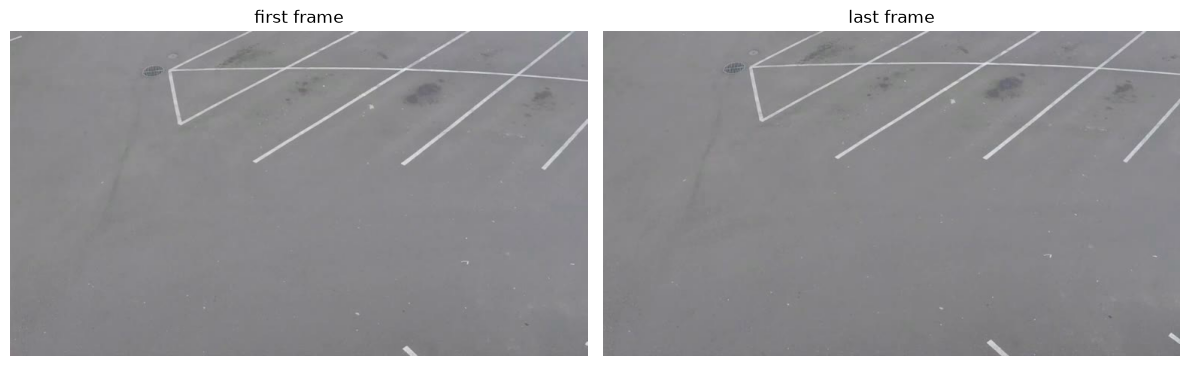

In [7]:
assert OUTPUT_VIDEO_PATH and Path(OUTPUT_VIDEO_PATH).exists(), "OUTPUT_VIDEO_PATH not set or file not found."

cap = cv2.VideoCapture(OUTPUT_VIDEO_PATH)
if not cap.isOpened():
    print("Cannot open video.")
else:
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

    cap.set(cv2.CAP_PROP_POS_FRAMES, 0)
    ok1, first_frame = cap.read()

    cap.set(cv2.CAP_PROP_POS_FRAMES, max(0, total_frames - 1))
    ok2, last_frame = cap.read()
    cap.release()

    if ok1 and ok2:
        first_frame = cv2.cvtColor(first_frame, cv2.COLOR_BGR2RGB)
        last_frame = cv2.cvtColor(last_frame, cv2.COLOR_BGR2RGB)

        plt.figure(figsize=(12, 5))
        plt.subplot(1, 2, 1); plt.imshow(first_frame); plt.title("first frame"); plt.axis("off")
        plt.subplot(1, 2, 2); plt.imshow(last_frame); plt.title("last frame"); plt.axis("off")
        plt.tight_layout(); plt.show()
    else:
        print("Cannot read frames.")

## Conclusions

In this lab, you built a multi-object tracking pipeline using YOLOv8 with ByteTrack. You learned how detection and data association work together to maintain consistent object identities across video frames, and visualized tracking results on real video sequences.

---

Copyright (C) 2025 Advanced Micro Devices, Inc. All rights reserved. Portions of this file consist of AI-generated content.
SPDX-License-Identifier: MIT